In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance

import joblib
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42


In [6]:

df = pd.read_excel("Online Retail.xlsx")

print("Dataset shape:", df.shape)
display(df.head())
df.info()


Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


In [7]:

data = df.copy()

data.columns = data.columns.str.strip()

data["InvoiceDate"] = pd.to_datetime(
    data["InvoiceDate"], errors="coerce"
)

data["CustomerID"] = data["CustomerID"].astype("string").str.strip()

data["Quantity"] = pd.to_numeric(
    data["Quantity"], errors="coerce"
)

data["UnitPrice"] = pd.to_numeric(
    data["UnitPrice"], errors="coerce"
)

print("Missing values before filtering:")
print(data.isnull().sum())

data = data.dropna(
    subset=["CustomerID", "InvoiceDate", "Quantity", "UnitPrice"]
)

data = data[
    (data["Quantity"] > 0) &
    (data["UnitPrice"] > 0) &
    (~data["InvoiceNo"].astype(str).str.startswith("C"))
].copy()

data["CustomerID"] = data["CustomerID"].astype(str)

data["Revenue"] = data["Quantity"] * data["UnitPrice"]

print("Cleaned shape:", data.shape)
display(data.head())


Missing values before filtering:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
Cleaned shape: (397884, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


Unique customers: 4338
Unique products: 3665
Total revenue: 8911407.9
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


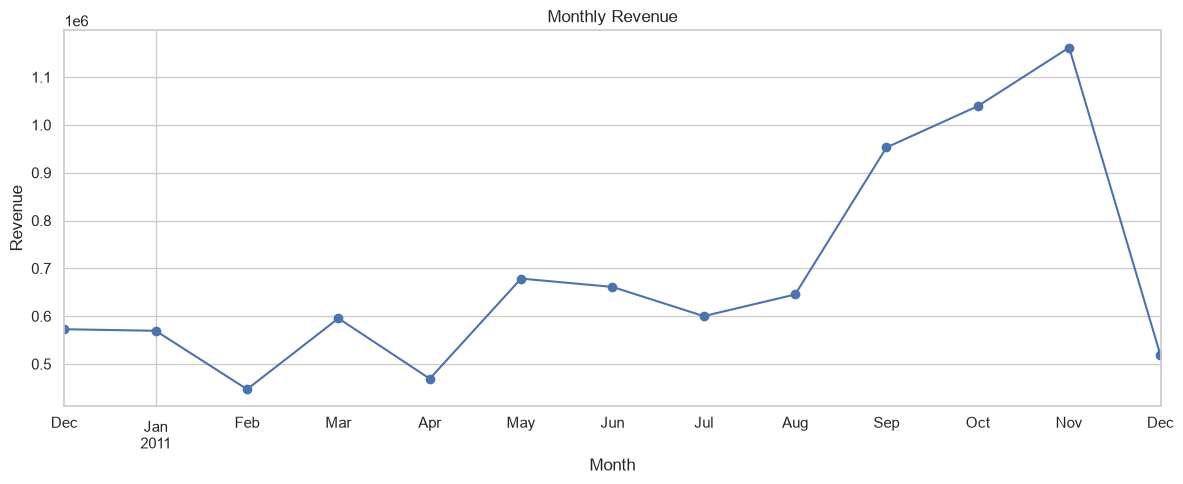

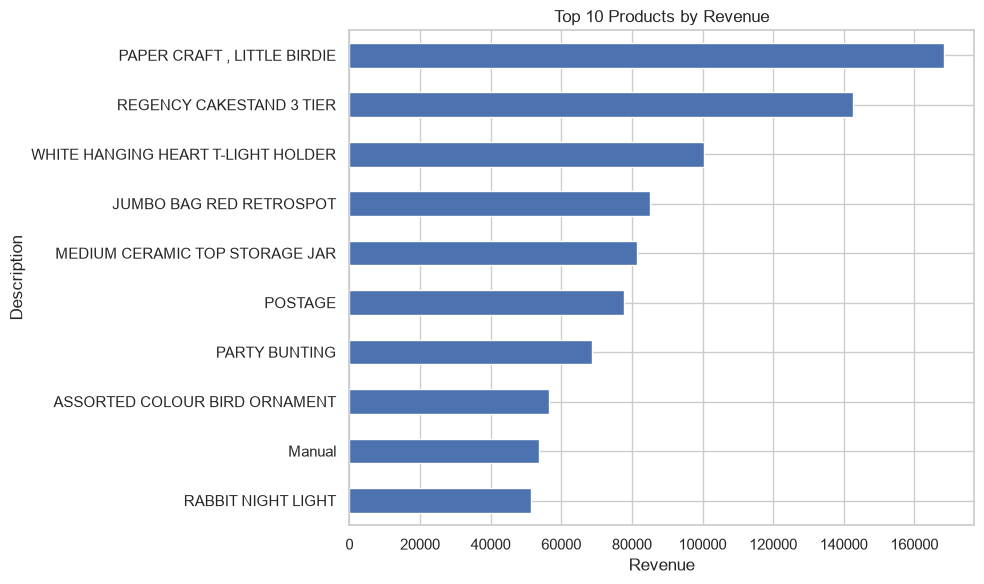

In [8]:

print("Unique customers:", data["CustomerID"].nunique())
print("Unique products:", data["StockCode"].nunique())
print("Total revenue:", round(data["Revenue"].sum(), 2))
print("Date range:", data["InvoiceDate"].min(),
      "to", data["InvoiceDate"].max())

monthly_sales = (
    data.set_index("InvoiceDate")["Revenue"]
    .resample("MS")
    .sum()
)

monthly_sales.plot(figsize=(12, 5), marker="o")
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

top_products = (
    data.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products.sort_values().plot(
    kind="barh", figsize=(10, 6)
)
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.tight_layout()
plt.show()


In [9]:

customer_features = data.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
    TotalQuantity=("Quantity", "sum"),
    AverageOrderValue=("Revenue", "sum")
)

order_counts = data.groupby("CustomerID")["InvoiceNo"].nunique()

customer_features["AverageOrderValue"] = (
    customer_features["Monetary"] / order_counts
)

customer_features["Recency"] = (
    data["InvoiceDate"].max() - customer_features["LastPurchase"]
).dt.days

customer_features["Frequency"] = customer_features["Frequency"].astype(int)

display(customer_features.head())


,LastPurchase,Frequency,Monetary,TotalQuantity,AverageOrderValue,Recency
CustomerID,,,,,,
12346.0,2011-01-18 10:01:00,1,77183.60,74215,77183.600000,325
12347.0,2011-12-07 15:52:00,7,4310.00,2458,615.714286,1
12348.0,2011-09-25 13:13:00,4,1797.24,2341,449.310000,74
12349.0,2011-11-21 09:51:00,1,1757.55,631,1757.550000,18
12350.0,2011-02-02 16:01:00,1,334.40,197,334.400000,309


In [10]:

cutoff_date = pd.Timestamp("2011-09-01")
observation_start = pd.Timestamp("2011-06-01")
prediction_end = pd.Timestamp("2011-12-10")

historical = data[
    (data["InvoiceDate"] >= observation_start) &
    (data["InvoiceDate"] < cutoff_date)
].copy()

future = data[
    (data["InvoiceDate"] >= cutoff_date) &
    (data["InvoiceDate"] < prediction_end)
].copy()

features = historical.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
    TotalQuantity=("Quantity", "sum")
)

features["Recency"] = (
    cutoff_date - features["LastPurchase"]
).dt.days

features["AverageOrderValue"] = (
    features["Monetary"] / features["Frequency"]
)

future_customers = set(future["CustomerID"].unique())

# Label 1 means no observed purchase in the future window.
features["Churn"] = (
    ~features.index.isin(future_customers)
).astype(int)

features = features.replace([np.inf, -np.inf], np.nan)
features = features.dropna(
    subset=["Recency", "Frequency", "Monetary",
            "TotalQuantity", "AverageOrderValue"]
)

print("Customer count:", len(features))
print("\nChurn label distribution:")
print(features["Churn"].value_counts())
print("\nChurn proportion:")
print(features["Churn"].value_counts(normalize=True))


Customer count: 1948

Churn label distribution:
Churn
0    1374
1     574
Name: count, dtype: int64

Churn proportion:
Churn
0    0.705339
1    0.294661
Name: proportion, dtype: float64


,Customers,AvgRecency,AvgFrequency,AvgMonetary,AvgOrderValue
Churn,,,,,
0,1374,34.810044,2.354440,1175.899826,429.384218
1,574,44.057491,1.339721,506.902857,348.320655


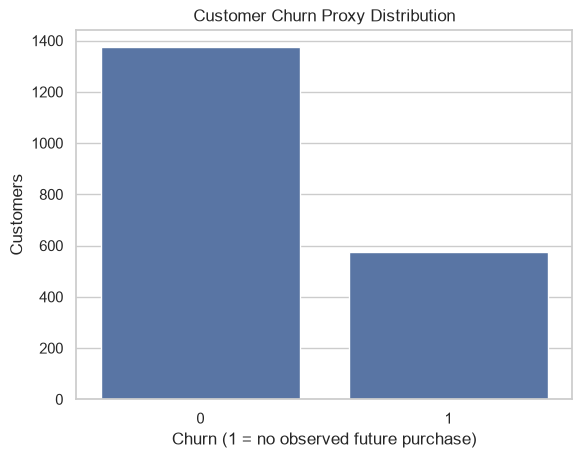

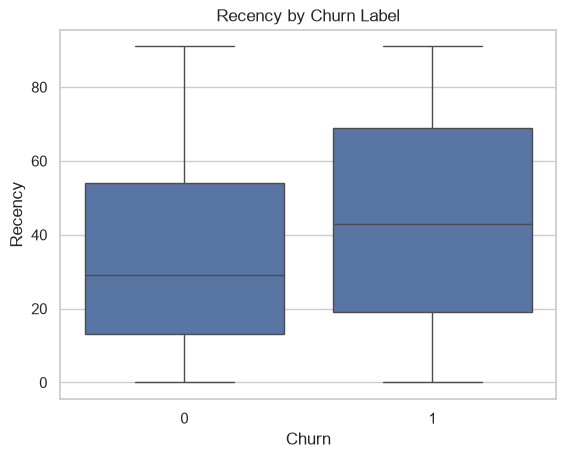

In [11]:

churn_summary = features.groupby("Churn").agg(
    Customers=("Churn", "size"),
    AvgRecency=("Recency", "mean"),
    AvgFrequency=("Frequency", "mean"),
    AvgMonetary=("Monetary", "mean"),
    AvgOrderValue=("AverageOrderValue", "mean")
)

display(churn_summary)

sns.countplot(data=features, x="Churn")
plt.title("Customer Churn Proxy Distribution")
plt.xlabel("Churn (1 = no observed future purchase)")
plt.ylabel("Customers")
plt.show()

sns.boxplot(data=features, x="Churn", y="Recency")
plt.title("Recency by Churn Label")
plt.show()


In [12]:

feature_columns = [
    "Recency",
    "Frequency",
    "Monetary",
    "TotalQuantity",
    "AverageOrderValue"
]

X = features[feature_columns]
y = features["Churn"]

if y.nunique() < 2 or y.value_counts().min() < 2:
    raise ValueError(
        "Dono classes mein kam se kam 2 customers chahiye. "
        "Label definition aur date windows inspect karo."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

models = {
    "Baseline": DummyClassifier(strategy="prior"),
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=RANDOM_STATE
        ))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            min_samples_leaf=5
        ))
    ])
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results[name] = {
        "model": model,
        "predictions": predictions,
        "probabilities": probabilities,
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "Average_Precision": average_precision_score(
            y_test, probabilities
        )
    }

    print(f"\n{'=' * 40}\n{name}")
    print(classification_report(
        y_test, predictions, zero_division=0
    ))
    print("ROC-AUC:", round(results[name]["ROC_AUC"], 3))
    print("Average Precision:",
          round(results[name]["Average_Precision"], 3))



Baseline
              precision    recall  f1-score   support

           0       0.71      1.00      0.83       344
           1       0.00      0.00      0.00       143

    accuracy                           0.71       487
   macro avg       0.35      0.50      0.41       487
weighted avg       0.50      0.71      0.58       487

ROC-AUC: 0.5
Average Precision: 0.294

Logistic Regression
              precision    recall  f1-score   support

           0       0.84      0.53      0.65       344
           1       0.40      0.76      0.53       143

    accuracy                           0.60       487
   macro avg       0.62      0.64      0.59       487
weighted avg       0.71      0.60      0.61       487

ROC-AUC: 0.688
Average Precision: 0.447

Random Forest
              precision    recall  f1-score   support

           0       0.76      0.63      0.69       344
           1       0.37      0.52      0.44       143

    accuracy                           0.60       487
   m

Selected model: Logistic Regression


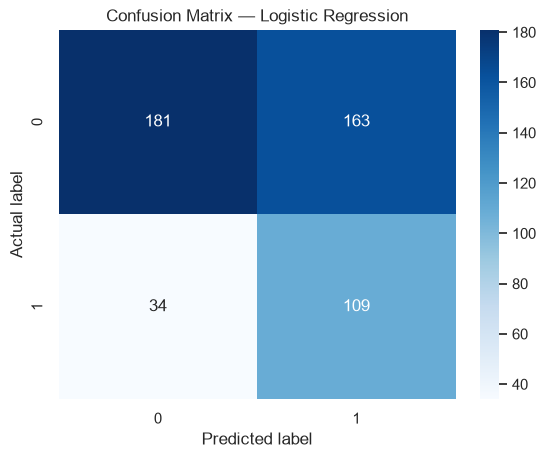

In [13]:

best_name = max(
    ["Logistic Regression", "Random Forest"],
    key=lambda name: results[name]["Average_Precision"]
)

best_model = results[best_name]["model"]
best_predictions = results[best_name]["predictions"]

print("Selected model:", best_name)

cm = confusion_matrix(y_test, best_predictions)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.show()


,Feature,Importance
1,Frequency,0.102900
4,AverageOrderValue,0.054368
3,TotalQuantity,0.038583
2,Monetary,0.034101
0,Recency,0.015763


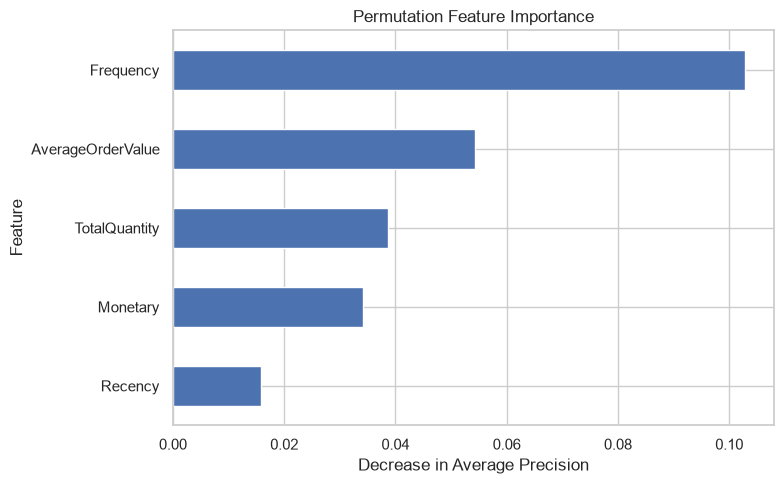

In [14]:

importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=5,
    random_state=RANDOM_STATE
)

importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

display(importance_df)

importance_df.sort_values("Importance").plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False,
    figsize=(8, 5)
)

plt.title("Permutation Feature Importance")
plt.xlabel("Decrease in Average Precision")
plt.tight_layout()
plt.show()


In [15]:

scored_customers = features.loc[X_test.index].copy()

scored_customers["ChurnProbability"] = (
    best_model.predict_proba(X_test)[:, 1]
)

scored_customers["RiskSegment"] = pd.cut(
    scored_customers["ChurnProbability"],
    bins=[-0.001, 0.33, 0.66, 1.001],
    labels=["Low", "Medium", "High"]
)

retention_summary = scored_customers.groupby(
    "RiskSegment", observed=False
).agg(
    Customers=("ChurnProbability", "size"),
    AverageRisk=("ChurnProbability", "mean"),
    AverageRevenue=("Monetary", "mean"),
    TotalHistoricalRevenue=("Monetary", "sum")
)

display(retention_summary)

display(
    scored_customers.sort_values(
        "ChurnProbability", ascending=False
    ).head(20)
)


,Customers,AverageRisk,AverageRevenue,TotalHistoricalRevenue
RiskSegment,,,,
Low,110,0.168434,2745.466273,302001.29
Medium,373,0.553784,444.744263,165889.61
High,4,0.677958,16506.875000,66027.50


,LastPurchase,Frequency,Monetary,TotalQuantity,Recency,AverageOrderValue,Churn,ChurnProbability,RiskSegment
CustomerID,,,,,,,,,
18102.0,2011-08-05 15:39:00,11,65895.12,14698,26,5990.465455,0,0.724537,High
15658.0,2011-06-02 15:22:00,1,7.50,2,90,7.500000,1,0.666035,High
13917.0,2011-06-01 12:46:00,1,65.38,38,91,65.380000,0,0.661060,High
13682.0,2011-06-05 14:06:00,1,59.50,10,87,59.500000,1,0.660202,High
13283.0,2011-06-07 12:39:00,1,25.50,30,85,25.500000,0,0.659397,Medium
16659.0,2011-06-03 15:03:00,1,39.12,72,89,39.120000,1,0.658888,Medium
16832.0,2011-06-08 15:36:00,1,62.50,5,84,62.500000,1,0.658078,Medium
13885.0,2011-06-03 15:07:00,1,107.65,23,89,107.650000,1,0.658024,Medium
12383.0,2011-06-08 08:02:00,1,99.45,20,84,99.450000,1,0.654906,Medium


In [16]:

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

joblib.dump(best_model, output_dir / "churn_model.joblib")

features.to_csv(
    output_dir / "customer_features_and_labels.csv"
)

scored_customers.to_csv(
    output_dir / "test_customer_risk_scores.csv"
)

importance_df.to_csv(
    output_dir / "feature_importance.csv",
    index=False
)

print("Model and analysis files saved in:", output_dir.resolve())


Model and analysis files saved in: C:\Users\jainv\Pratice\outputs
